# 06 · Explainability: What Drives a Used Car's Price?

**Goal:** open up the best model from notebook 05 (Random Forest) and answer two questions:

1. **Can we trust its lead?** Notebook 05 raised a doubt: part of Random Forest's advantage over Gradient Boosting
   may come from near-identical listings (the same car re-posted with a slightly changed price or mileage).
2. **What does it use to set a price?** Using the three explainability tools from lesson 16: **feature importance**,
   **partial dependence plots** and **SHAP values**.

The Random Forest is refit with the tuned settings from `results/best_params.json` (same split, same features, same
random seed as notebook 05), so it is the same model. Linear Regression on `log(price)` is refit too, as the
"simple" model to compare against.

⏱️ *Runtime: about 10 minutes.*

In [1]:
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import PartialDependenceDisplay, partial_dependence

sys.path.append('../src')
from prep import (load_data, split, add_model_top, tree_preprocessor, linear_preprocessor,
                  NUM_COLS, CAT_COLS, MODEL_COL, RANDOM_STATE)

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
X_train, X_test = add_model_top(X_train, X_test)
y_train_log = np.log(y_train)

best = json.load(open('../results/best_params.json'))['Random Forest']
rf_params = {k.split('__')[1]: v for k, v in best.items()}
print('Random Forest settings:', rf_params)

t = time.time()
rf = make_pipeline(tree_preprocessor(),
                   RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **rf_params))
rf.fit(X_train, y_train_log)
lr = make_pipeline(linear_preprocessor(), LinearRegression()).fit(X_train, y_train_log)
print(f'fit time: {time.time() - t:.0f} s')

# Test predictions from notebook 05 (same row order as y_test) plus the two refit models
preds = pd.read_csv('../results/test_predictions.csv')
assert (preds['price'].values == y_test.values).all()
preds['Linear Regression'] = np.exp(lr.predict(X_test)).round(0)
rf_check = np.exp(rf.predict(X_test)).round(0)
print('Refit Random Forest matches notebook 05:', np.allclose(rf_check, preds['Random Forest'], atol=1))

Random Forest settings: {'max_features': 0.3, 'min_samples_leaf': 1}


fit time: 93 s


Refit Random Forest matches notebook 05: True


## 1. Does Random Forest's lead hold on truly new cars?

A test car has a **near twin** in training when the training set holds a listing with the **same manufacturer,
model and model year, and a mileage within 1%** (at least 100 miles). Such a pair is often the same car posted
twice with an edited price or mileage, which the exact-match repost rule in `src/clean.py` cannot catch; it can
also be two genuinely similar cars (for example a dealer selling several of the same rental model).

If a model's lead comes mostly from cars with a near twin, it is partly "remembering" listings rather than pricing
new ones. The fair comparison is on the cars **without** a near twin.

In [2]:
cols = ['manufacturer', 'model', 'year', 'odometer']
tr = X_train[cols].dropna(subset=['model', 'odometer'])
te = X_test[cols].reset_index(drop=True).reset_index().dropna(subset=['model', 'odometer'])
pairs = te.merge(tr, on=['manufacturer', 'model', 'year'], suffixes=('', '_train'))
close = (pairs['odometer'] - pairs['odometer_train']).abs() <= np.maximum(0.01 * pairs['odometer'], 100)

has_twin = np.zeros(len(X_test), dtype=bool)
has_twin[pairs.loc[close, 'index'].unique()] = True
print(f'Test cars with a near twin in training: {has_twin.sum():,} of {len(X_test):,} ({has_twin.mean():.1%})')

models = ['Linear Regression', 'Decision Tree', 'Gradient Boosting', 'Random Forest']
rows = []
for name in models:
    err = (preds[name] - preds['price']).abs()
    rows.append({'model': name, 'all test cars': err.mean(),
                 'with near twin': err[has_twin].mean(), 'no near twin': err[~has_twin].mean()})
twin = pd.DataFrame(rows).set_index('model').round(0)
twin['share of error drop on twins'] = ((twin['no near twin'] - twin['with near twin']) / twin['no near twin'] * 100).round(1)
twin.to_csv('../results/near_twin_check.csv')
twin

Test cars with a near twin in training: 10,659 of 41,529 (25.7%)


,all test cars,with near twin,no near twin,share of error drop on twins
model,,,,
Linear Regression,4151.0,3314.0,4440.0,25.4
Decision Tree,4196.0,3468.0,4447.0,22.0
Gradient Boosting,3303.0,2600.0,3546.0,26.7
Random Forest,3231.0,2383.0,3524.0,32.4


**Reading the table:**

- **10,659 test cars (25.7%) have a near twin** in the training set.
- **Every model is more accurate on those cars, even Linear Regression** (25% lower error), which cannot memorise single
  listings. So part of the drop is simply that cars with a near twin are common cars (popular models, typical
  mileage) that are easy to price.
- **Random Forest gains the most** (32% lower error on twins, against 27% for Gradient Boosting). With one-car leaves,
  it can copy the price of a near-identical listing it saw in training.
- **On cars without a near twin, the two ensembles are tied:** Random Forest \$3,524 vs Gradient Boosting \$3,546,
  a \$22 gap (against \$72 on the whole test set and \$217 on the twins).

**Conclusion:** most of Random Forest's lead came from near-identical listings. For a genuinely new listing the
realistic typical error is **about \$3,500 (29% of the median price)**, not \$3,231. That is still 21% better than
Linear Regression on the same cars (\$4,440). Random Forest stays the main model: it is never worse than Gradient
Boosting and trains in 1.5 minutes instead of 42.

## 2. Feature importance (lesson 16)

A tree-based model's `feature_importances_` measures how much each column reduces the error (here the squared error
of `log(price)`) across all the splits in all the trees. The one-hot encoder turns each category into its own
column, so the first chart shows single columns, and the second adds up the columns of each original feature.

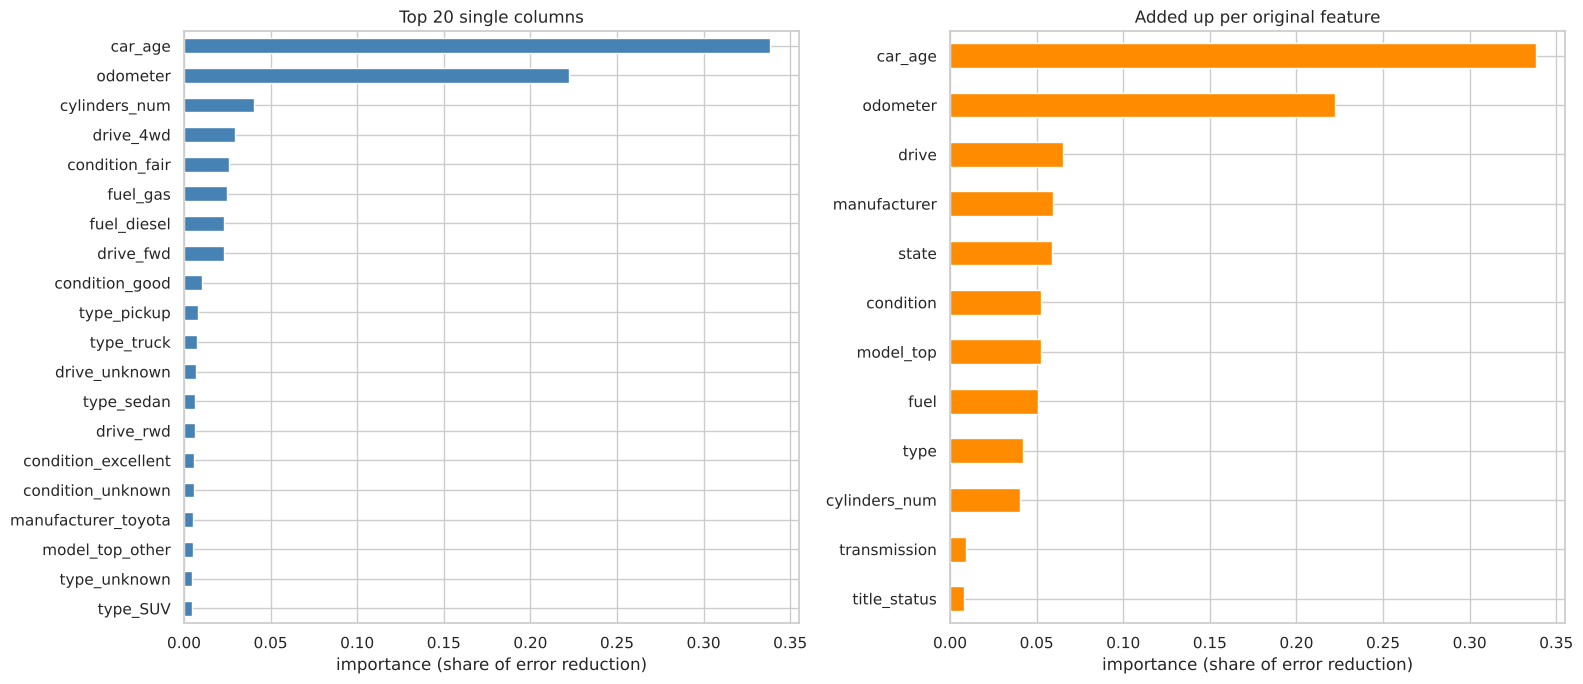

,car_age,odometer,drive,manufacturer,state,condition,model_top,fuel,type,cylinders_num,transmission,title_status
importance_%,33.8,22.2,6.5,5.9,5.9,5.3,5.2,5.1,4.2,4.1,0.9,0.8


In [3]:
names = rf[0].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values(ascending=False)

def original(col):
    # map a one-hot column such as "fuel_diesel" back to its feature ("fuel")
    for f in NUM_COLS + CAT_COLS + [MODEL_COL]:
        if col == f or col.startswith(f + '_'):
            return f
grouped = imp.groupby(imp.index.map(original)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
imp.head(20)[::-1].plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Top 20 single columns')
grouped[::-1].plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Added up per original feature')
for ax in axes:
    ax.set_xlabel('importance (share of error reduction)')
plt.tight_layout()
plt.show()
(grouped * 100).round(1).rename('importance_%').to_frame().T

**What the importances say:**

- **Age (33.8%) and mileage (22.2%) do more than half of the work** (56% of the error reduction). Every other feature
  adds 4–7%, and transmission and title status less than 1% each.
- The strongest single categories after age and mileage are cylinders, `drive_4wd`, `condition_fair`, diesel vs gas
  and `drive_fwd`: the "truck vs small car" signals.
- **A caution:** this importance is measured on the *training* data, and it favours features with many levels, because
  they offer many ways to split. `state` (51 levels) gets 5.9%, the same as `manufacturer`. SHAP, measured on test
  cars in section 4, ranks `state` much lower.

## 3. Partial dependence plots (lesson 16)

A partial dependence plot answers *"if we change only this feature and keep everything else about each car the
same, how does the predicted price move?"* Each thin line is one car (individual conditional expectation, ICE); the
thick line is their average. The model predicts `log(price)`, so the y-axis is in log units; a rise of 0.1 means
about 10% more.

The plots use a random sample of 2,000 training cars to keep them fast.

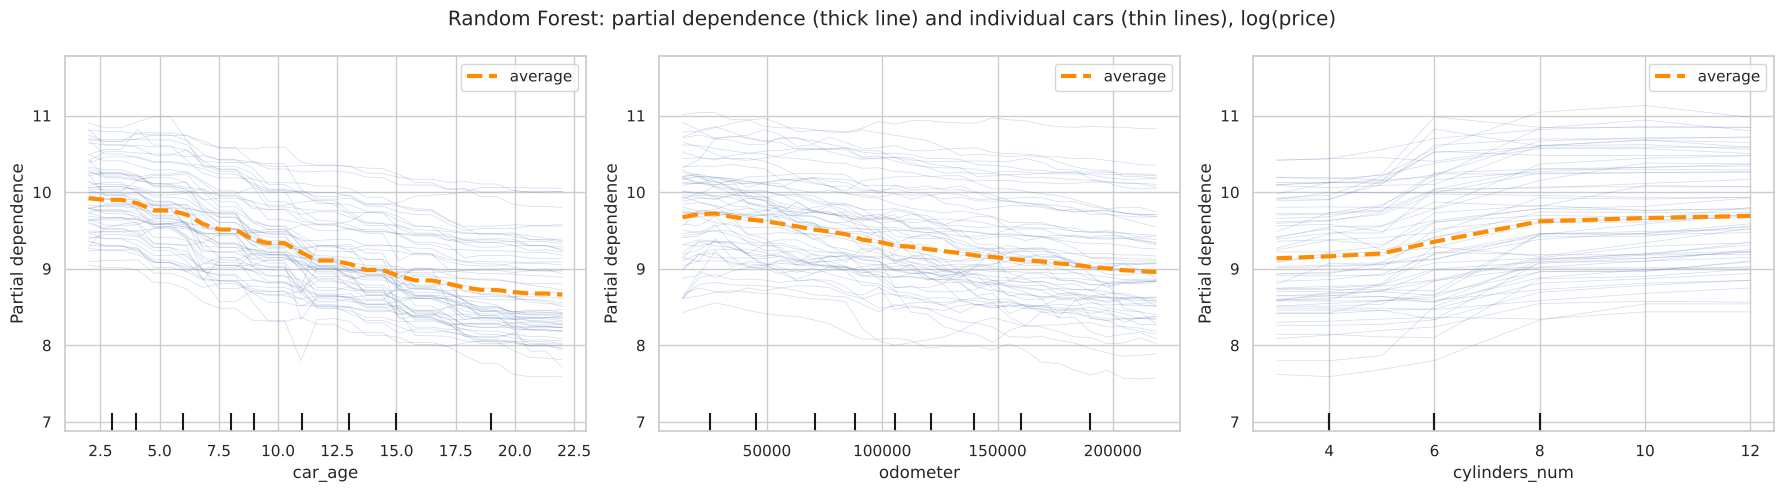

In [4]:
pd_sample = X_train.sample(2_000, random_state=RANDOM_STATE)
for c in CAT_COLS + [MODEL_COL]:
    # the pipeline's imputer turns missing categories into "unknown"; doing it here first gives the same predictions
    pd_sample[c] = pd_sample[c].fillna('unknown')
int_cols = pd_sample.select_dtypes('integer').columns
pd_sample[int_cols] = pd_sample[int_cols].astype(float)   # partial_dependence needs float columns (car_age is int)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
PartialDependenceDisplay.from_estimator(
    rf, pd_sample, features=['car_age', 'odometer', 'cylinders_num'], kind='both',
    subsample=60, random_state=RANDOM_STATE, grid_resolution=30, ax=ax,
    ice_lines_kw={'alpha': 0.25}, pd_line_kw={'color': 'darkorange', 'linewidth': 3})
plt.suptitle('Random Forest: partial dependence (thick line) and individual cars (thin lines), log(price)')
plt.tight_layout()
plt.show()

### In dollars, compared with Linear Regression

The same average curves turned back into dollars with `exp` (this gives the *typical* price, the geometric mean),
side by side with the Linear Regression model, which can only draw a straight line on the log scale.

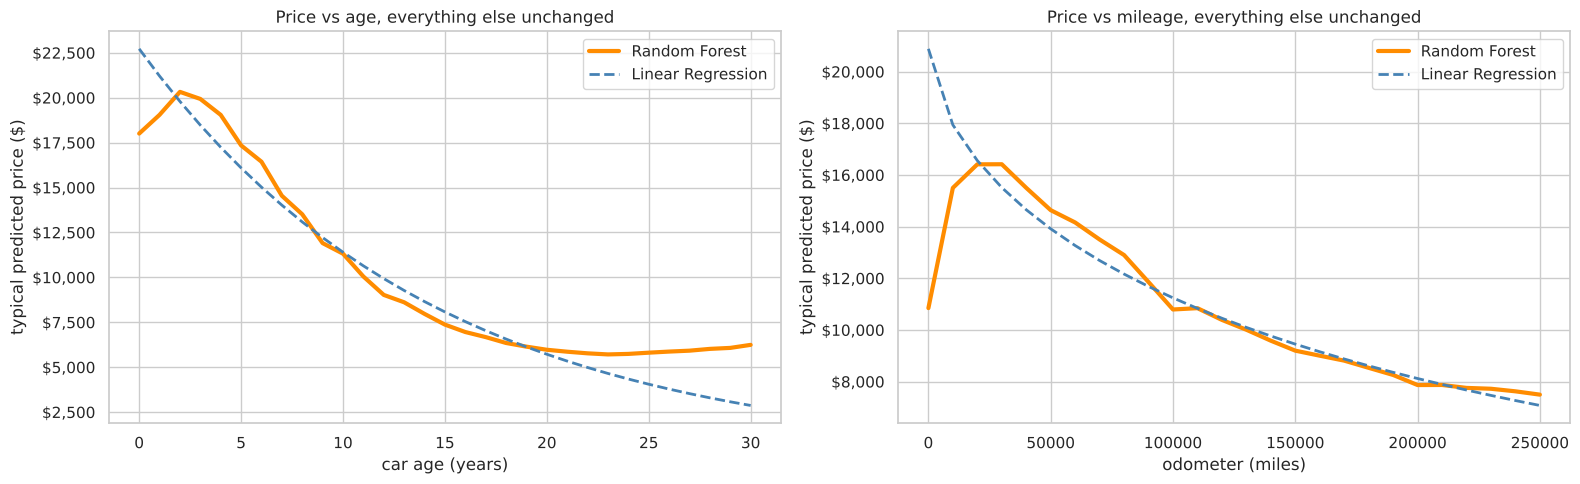

,typical price,change vs one year younger (%)
0,18010.0,NaN
1,19050.0,5.8
2,20330.0,6.7
3,19930.0,-1.9
5,17350.0,-8.9
8,13510.0,-7.1
10,11320.0,-5.0
12,9020.0,-10.2
15,7370.0,-7.5
20,5970.0,-2.8


In [5]:
def pd_dollars(model, feature, grid=None):
    res = partial_dependence(model, pd_sample, [feature], kind='average',
                             grid_resolution=30, custom_values={feature: grid} if grid is not None else None)
    return pd.Series(np.exp(res['average'][0]), index=res['grid_values'][0])

age_grid = np.arange(0, 31)
odo_grid = np.arange(0, 250_001, 10_000)
curves = {
    'age': (pd_dollars(rf, 'car_age', age_grid), pd_dollars(lr, 'car_age', age_grid)),
    'odometer': (pd_dollars(rf, 'odometer', odo_grid), pd_dollars(lr, 'odometer', odo_grid)),
}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (key, (r, l)), xlabel in zip(axes, curves.items(), ['car age (years)', 'odometer (miles)']):
    ax.plot(r.index, r.values, label='Random Forest', color='darkorange', linewidth=3)
    ax.plot(l.index, l.values, label='Linear Regression', color='steelblue', linestyle='--', linewidth=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('typical predicted price ($)')
    ax.yaxis.set_major_formatter(lambda v, _: f'${v:,.0f}')
    ax.legend()
axes[0].set_title('Price vs age, everything else unchanged')
axes[1].set_title('Price vs mileage, everything else unchanged')
plt.tight_layout()
plt.show()

age_rf = curves['age'][0]
table = pd.DataFrame({'typical price': age_rf.round(-1),
                      'change vs one year younger (%)': (age_rf.pct_change() * 100).round(1)})
table.loc[[0, 1, 2, 3, 5, 8, 10, 12, 15, 20, 25, 30]]

In [6]:
odo_rf = curves['odometer'][0]
pd.DataFrame({'typical price': odo_rf.round(-1),
              'change vs 10k miles fewer (%)': (odo_rf.pct_change() * 100).round(1)}).loc[
    [0, 10_000, 30_000, 50_000, 80_000, 100_000, 150_000, 200_000, 250_000]]

,typical price,change vs 10k miles fewer (%)
0,10850.0,NaN
10000,15500.0,42.9
30000,16420.0,0.0
50000,14640.0,-5.6
80000,12900.0,-4.5
100000,10790.0,-9.0
150000,9200.0,-4.0
200000,7870.0,-4.7
250000,7500.0,-1.7


### Categorical features

For a category, partial dependence sets *every* car in the sample to one level (for example, all 2,000 cars
"salvage"), predicts, and averages. The bars show the typical price for each level, all else unchanged.

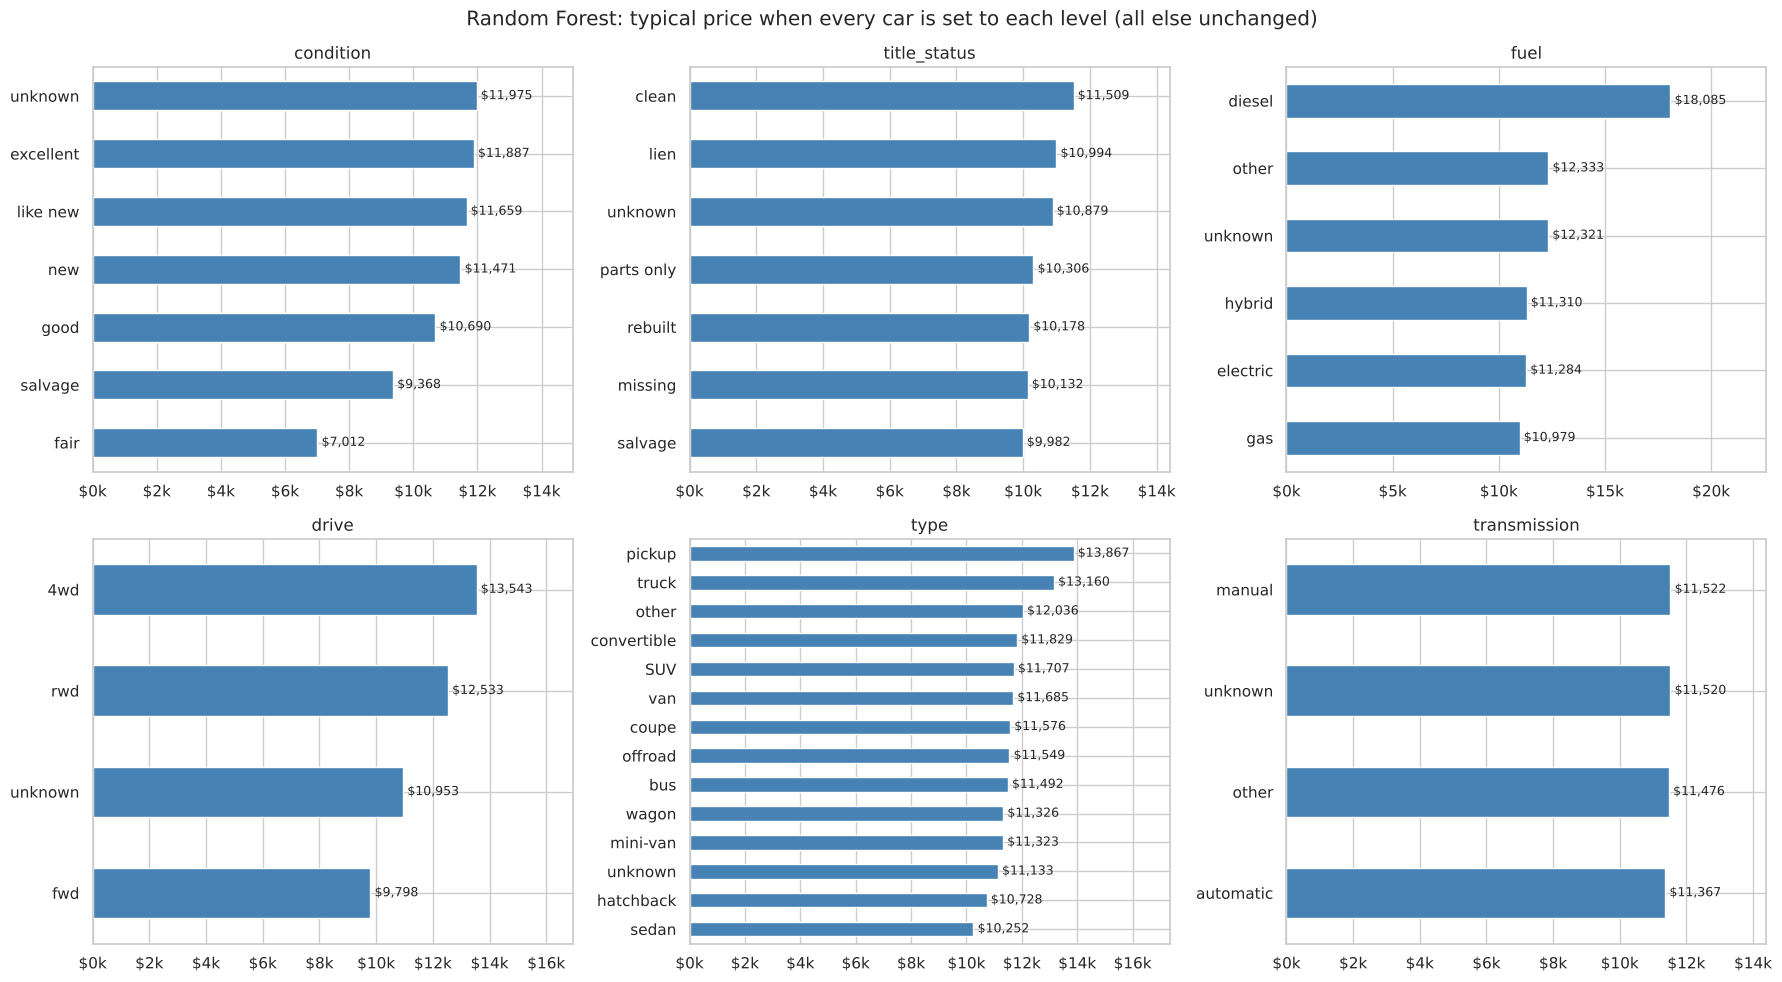

In [7]:
cat_feats = ['condition', 'title_status', 'fuel', 'drive', 'type', 'transmission']
cat_pd = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, f in zip(axes.ravel(), cat_feats):
    res = partial_dependence(rf, pd_sample, [f], categorical_features=[f], kind='average')
    s = pd.Series(np.exp(res['average'][0]), index=res['grid_values'][0]).sort_values()
    cat_pd[f] = s
    s.plot.barh(ax=ax, color='steelblue')
    ax.set_title(f)
    ax.xaxis.set_major_formatter(lambda v, _: f'${v / 1000:.0f}k')
    ax.bar_label(ax.containers[0], labels=[f'${v:,.0f}' for v in s], padding=3, fontsize=9)
    ax.set_xlim(0, s.max() * 1.25)
plt.suptitle('Random Forest: typical price when every car is set to each level (all else unchanged)')
plt.tight_layout()
plt.show()

In [8]:
# Size of each effect: highest level vs lowest level, and vs the most common level
summary = []
for f, s in cat_pd.items():
    common = X_train[f].fillna('unknown').mode()[0]
    summary.append({'feature': f, 'lowest': f'{s.index[0]} (${s.iloc[0]:,.0f})',
                    'highest': f'{s.index[-1]} (${s.iloc[-1]:,.0f})',
                    'most common level': f'{common} (${s[common]:,.0f})',
                    'spread ($)': round(s.iloc[-1] - s.iloc[0], -1)})
pd.DataFrame(summary).sort_values('spread ($)', ascending=False)

,feature,lowest,highest,most common level,spread ($)
2,fuel,"gas ($10,979)","diesel ($18,085)","gas ($10,979)",7110.0
0,condition,"fair ($7,012)","unknown ($11,975)","unknown ($11,975)",4960.0
3,drive,"fwd ($9,798)","4wd ($13,543)","4wd ($13,543)",3740.0
4,type,"sedan ($10,252)","pickup ($13,867)","unknown ($11,133)",3610.0
1,title_status,"salvage ($9,982)","clean ($11,509)","clean ($11,509)",1530.0
5,transmission,"automatic ($11,367)","manual ($11,522)","automatic ($11,367)",160.0


**What the partial dependence plots show:**

**Age:** the forest's typical price falls fastest between about 5 and 15 years old, 5–10% a year
(\$19,930 at 3 years → \$11,320 at 10 → \$7,370 at 15). After about 20 years the curve **flattens and even rises**
(\$5,970 at 20, \$5,810 at 25, \$6,240 at 30), because older cars that are still listed tend to be kept or
collectible ones. This matches the EDA, where median price bottomed around model year 2000. Linear Regression can
only keep falling 6.7% a year (about \$2,900 at 30 years), which is why notebook 04 found it under-predicts cars older
than 25. The dip at 0–1 years should not be trusted: only 820 listings in the clean data are model year 2021.

**Mileage:** between 30,000 and 200,000 miles the typical price falls from \$16,420 to \$7,870, about 4–9% per
10,000 miles after 40,000, almost the same as Linear Regression. **Below 10,000 miles the forest predicts *lower* prices**
(\$10,850 at 0 miles). This is a data problem, not a real effect: in the clean data, 1,152 cars aged 8 or more show
1,000 miles or less, with a median price of \$5,499. These are most likely sellers typing "150" for 150,000 miles.
The forest learned "almost no miles = cheap old car". A fixed rule that treats such readings as missing is a
candidate fix for a later version (added to `docs/04`).

**Cylinders:** flat from 3 to 5 cylinders, then up for 6 and 8 (8 cylinders is roughly 60% above 4), flat after that.

**Categories (all else unchanged):**

| Feature | Lowest | Highest | Gap |
| --- | --- | --- | --- |
| fuel | gas \$10,979 | diesel \$18,085 | +65% |
| drive | fwd \$9,798 | 4wd \$13,543 | +38% |
| type | sedan \$10,252 | pickup \$13,867 | +35% |
| condition | fair \$7,012 | unknown \$11,975 | +71% |
| title_status | salvage \$9,982 | clean \$11,509 | +15% |
| transmission | automatic \$11,367 | manual \$11,522 | ~0 |

- **Diesel is the largest category effect**, then 4wd and pickup, all "work truck" features.
- **Condition:** "unknown" (missing) is at the top with excellent and like new, matching the EDA finding that listings
  without a condition are pricier (often dealers). "New" (\$11,471) does not beat "like new", and "salvage" condition
  (\$9,368) sits above "fair": both are rare (746 and 358 listings), so the trees seldom split on them.
- **Title status matters less than expected** (salvage only 13% below clean). Salvage-title cars are also older and
  have more miles; once those are held fixed, the title adds little, and with 1.4% of listings the trees rarely use it.
- **Transmission has no effect** once everything else is known.

## 4. SHAP values (lesson 16)

SHAP splits **one car's prediction** into a contribution from each feature: starting from the average prediction,
each feature pushes the price up or down, and the pushes add up exactly to the model's prediction for that car.

As in the lesson, `shap.KernelExplainer` is used. It works with any model through its `predict` function, so it can
explain the **12 original features** (age, mileage, make, condition, ...) instead of the 439 one-hot columns.
To pass the data through SHAP, which needs numbers, each category is coded as a number and decoded back before the
pipeline predicts. (`shap.TreeExplainer` is faster for trees, but this forest's trees are over 100 levels deep and
its results overflow.)

Contributions are in `log(price)` units: a contribution of −0.30 means the feature lowers that car's price by
about 26% (`exp(−0.30) − 1`).

In [9]:
FEATS = NUM_COLS + CAT_COLS + [MODEL_COL]
CATS = CAT_COLS + [MODEL_COL]
levels = {c: pd.Index(X_train[c].fillna('unknown').unique()) for c in CATS}

def encode(X):
    Z = X[FEATS].copy()
    for c in CATS:
        Z[c] = levels[c].get_indexer(Z[c].fillna('unknown'))
    return Z.astype(float).values

def decode(Z):
    X = pd.DataFrame(Z, columns=FEATS)
    for c in CATS:
        X[c] = levels[c][X[c].astype(int)].values
    return X

predict_log = lambda Z: rf.predict(decode(Z))

background = shap.sample(encode(X_train), 50, random_state=RANDOM_STATE)
explainer = shap.KernelExplainer(predict_log, background)

explain_idx = X_test.sample(300, random_state=RANDOM_STATE).index
Z_explain = encode(X_test.loc[explain_idx])
t = time.time()
shap_values = explainer.shap_values(Z_explain, nsamples=1000, silent=True)
print(f'SHAP for {len(explain_idx)} test cars: {time.time() - t:.0f} s')
gap = np.abs(shap_values.sum(1) + explainer.expected_value - predict_log(Z_explain)).max()
print(f'Contributions add up to the prediction (largest gap {gap:.1e})')
print(f'Average prediction (starting point): exp({explainer.expected_value:.2f}) = ${np.exp(explainer.expected_value):,.0f}')

SHAP for 300 test cars: 274 s
Contributions add up to the prediction (largest gap 3.6e-15)
Average prediction (starting point): exp(9.41) = $12,161


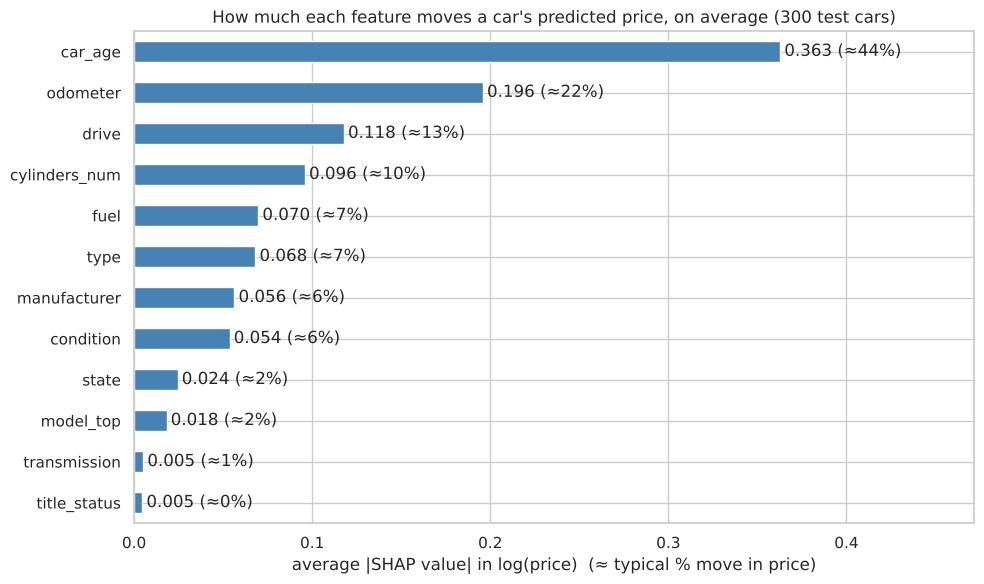

In [10]:
mean_abs = pd.Series(np.abs(shap_values).mean(0), index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
mean_abs.plot.barh(ax=ax, color='steelblue')
ax.bar_label(ax.containers[0], labels=[f'{v:.3f} (≈{(np.exp(v) - 1) * 100:.0f}%)' for v in mean_abs], padding=3)
ax.set_xlim(0, mean_abs.max() * 1.3)
ax.set_xlabel('average |SHAP value| in log(price)  (≈ typical % move in price)')
ax.set_title('How much each feature moves a car\'s predicted price, on average (300 test cars)')
plt.tight_layout()
plt.show()

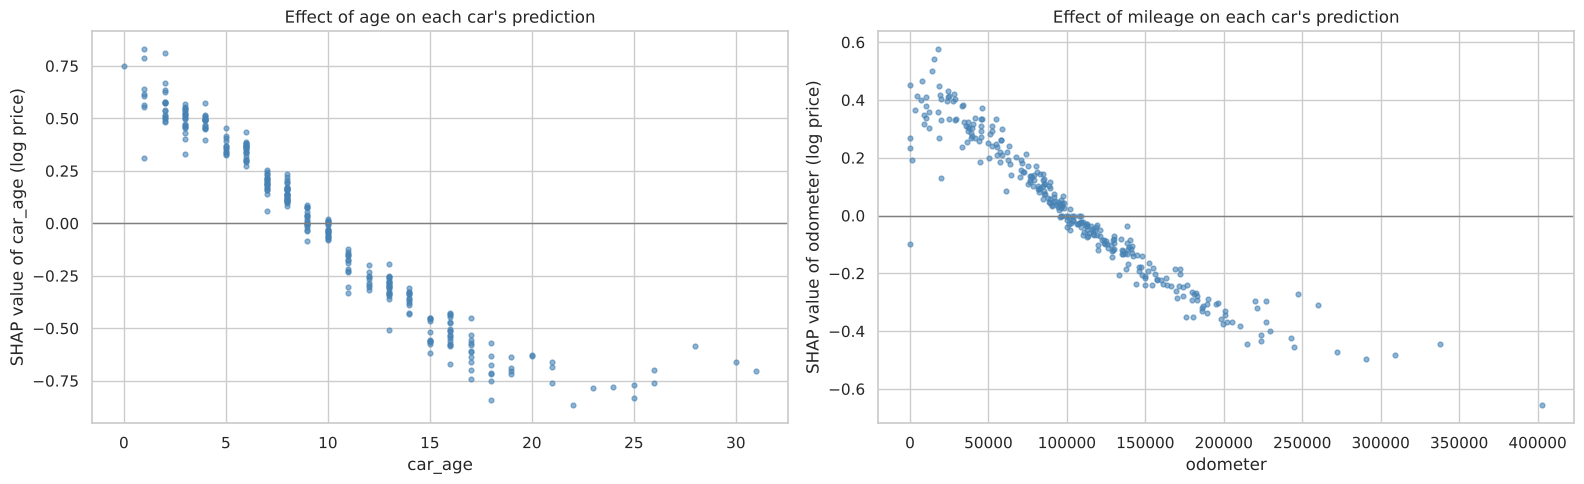

In [11]:
X_explain = X_test.loc[explain_idx]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, f in zip(axes, ['car_age', 'odometer']):
    i = FEATS.index(f)
    ax.scatter(X_explain[f], shap_values[:, i], s=12, alpha=0.6, color='steelblue')
    ax.axhline(0, color='grey', linewidth=1)
    ax.set_xlabel(f)
    ax.set_ylabel(f'SHAP value of {f} (log price)')
axes[0].set_title('Effect of age on each car\'s prediction')
axes[1].set_title('Effect of mileage on each car\'s prediction')
plt.tight_layout()
plt.show()

### Three example cars

One car picked at random from each of three price ranges. Each bar is one feature's push up (red) or down (blue)
from the average prediction `E[f(X)]` to this car's prediction `f(x)`, both in `log(price)`.

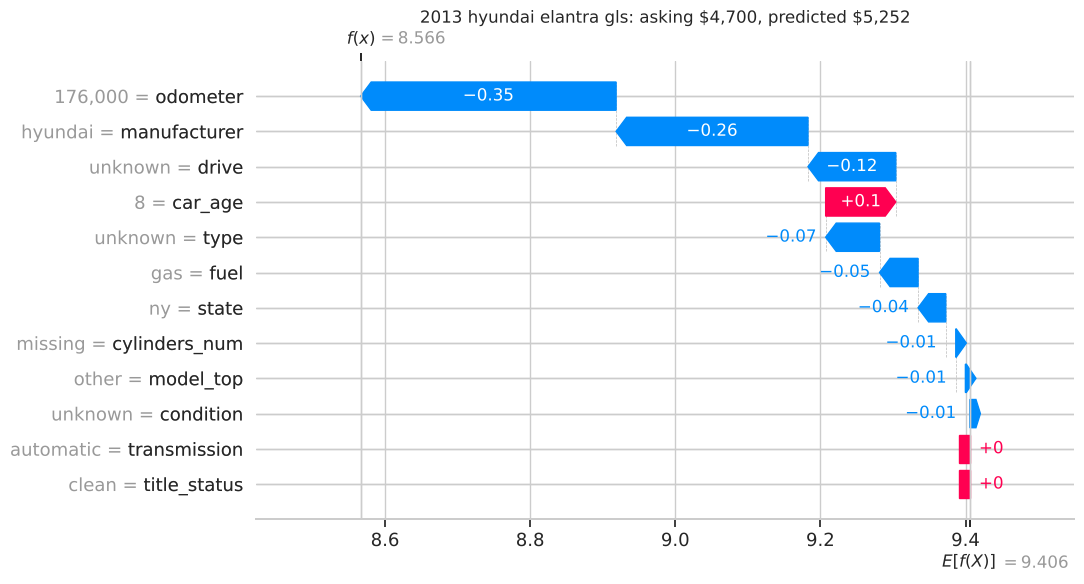

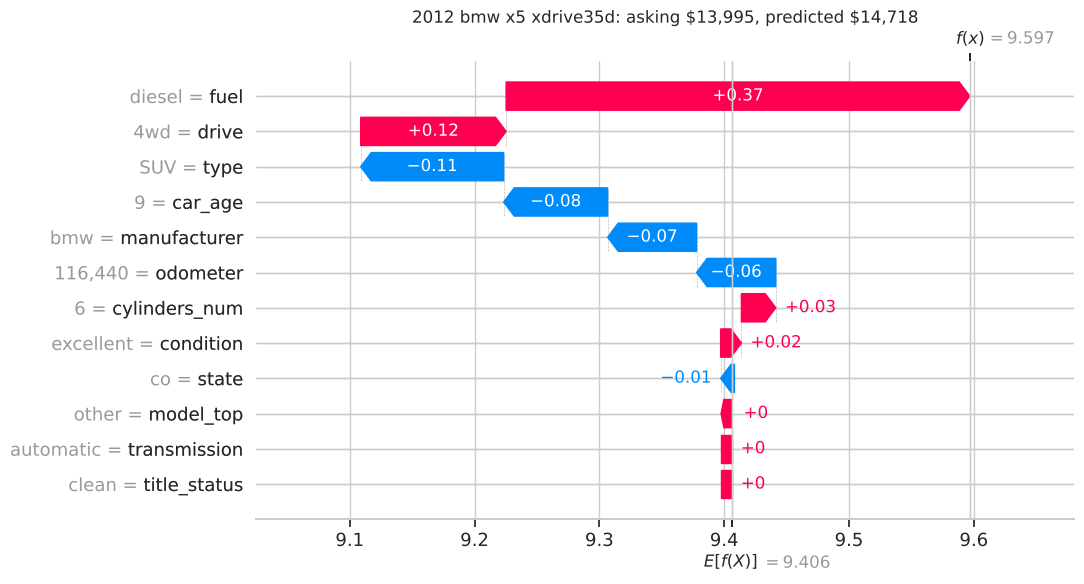

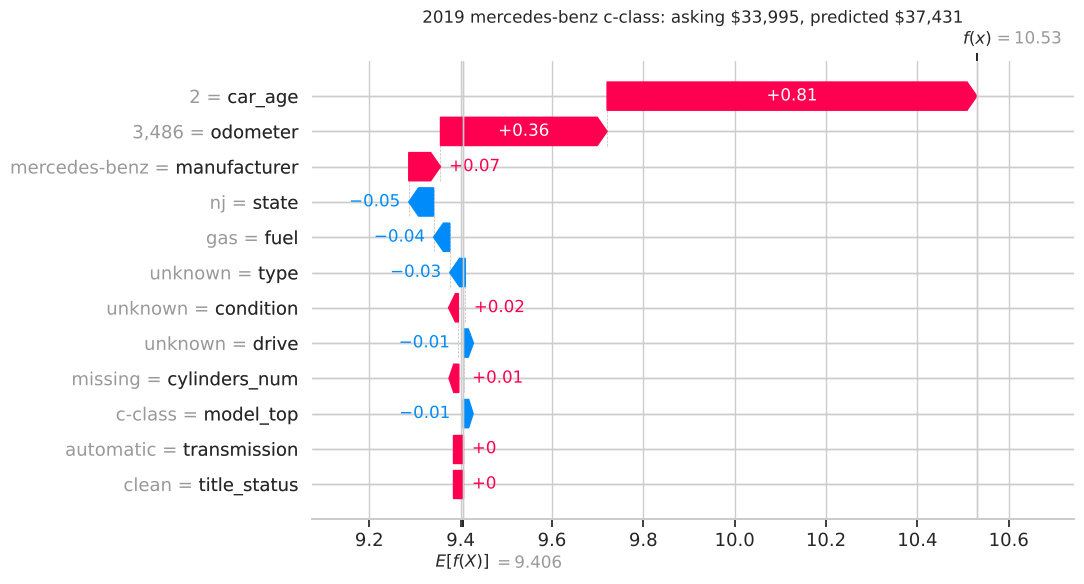

In [12]:
rng = np.random.RandomState(RANDOM_STATE)
price_explain = y_test.loc[explain_idx]
examples = []
for low, high in [(3_000, 8_000), (12_000, 20_000), (30_000, 60_000)]:
    pool = np.where((price_explain >= low) & (price_explain < high))[0]
    examples.append(rng.choice(pool))

display_data = decode(Z_explain).astype(object)
display_data['car_age'] = display_data['car_age'].astype(int)
display_data['odometer'] = display_data['odometer'].map(lambda v: 'missing' if np.isnan(v) else f'{v:,.0f}')
display_data['cylinders_num'] = display_data['cylinders_num'].map(lambda v: 'missing' if np.isnan(v) else int(v))

for i in examples:
    exp_i = shap.Explanation(values=shap_values[i], base_values=explainer.expected_value,
                             data=display_data.iloc[i].values, feature_names=FEATS)
    shap.plots.waterfall(exp_i, max_display=12, show=False)
    car = X_explain.iloc[i]
    plt.title(rf"{int(car['year'])} {car['manufacturer']} {car['model']}: asking \${price_explain.iloc[i]:,.0f}, "
              rf"predicted \${np.exp(predict_log(Z_explain[[i]]))[0]:,.0f}")   # \$ = a plain dollar sign in matplotlib
    plt.gcf().set_size_inches(11, 6)
    plt.tight_layout()
    plt.show()

**What SHAP shows:**

- **Same top three as feature importance:** age moves a car's predicted price by about 44% on average, mileage by
  22%, drive by 13%. Then cylinders (10%), fuel and type (7%), manufacturer and condition (6%). **State, model,
  transmission and title status move it by 2% or less.** `model_top` adds little because make, type, drive and
  cylinders already describe most models, and 45% of cars fall in its "other" group.
- **Age, car by car:** a near-straight fall from about +0.6 to +0.8 at 1–2 years to about −0.75 at 18 years, then
  flat. **Mileage:** a steady fall to about −0.4 at 200,000 miles. Both match the partial dependence curves.
- **The three example cars:**
  - *2013 Hyundai Elantra* (asking \$4,700, predicted \$5,252): its 176,000 miles pull the price down 0.35 (about
    −30%), and the Hyundai brand another 0.26 (about −23%).
  - *2012 BMW X5 diesel* (asking \$13,995, predicted \$14,718): diesel is the largest push, +0.37 (about +45%),
    plus 4wd +0.12; being an SUV takes off 0.11, age and mileage a little more.
  - *2019 Mercedes C-Class* (asking \$33,995, predicted \$37,431): being only 2 years old adds 0.81 (about
    +125%) and 3,486 miles another 0.36 (about +43%).

`KernelExplainer` estimates the values by sampling, so single contributions can move by about ±0.01 between runs.

## 5. The three tools side by side

In [13]:
ranking = pd.DataFrame({
    'impurity importance (%)': (grouped * 100).round(1),
    'mean |SHAP| (log price)': pd.Series(np.abs(shap_values).mean(0), index=FEATS).round(3),
})
ranking['rank by importance'] = ranking['impurity importance (%)'].rank(ascending=False).astype(int)
ranking['rank by SHAP'] = ranking['mean |SHAP| (log price)'].rank(ascending=False).astype(int)
ranking = ranking.sort_values('rank by SHAP')
ranking.rename_axis('feature').to_csv('../results/feature_importance.csv')
ranking

,impurity importance (%),mean |SHAP| (log price),rank by importance,rank by SHAP
car_age,33.8,0.363,1,1
odometer,22.2,0.196,2,2
drive,6.5,0.118,3,3
cylinders_num,4.1,0.096,10,4
fuel,5.1,0.070,8,5
type,4.2,0.068,9,6
manufacturer,5.9,0.056,4,7
condition,5.3,0.054,6,8
state,5.9,0.024,4,9
model_top,5.2,0.018,7,10


## Summary

**1. Can we trust Random Forest's lead?** Only partly. On the 74% of test cars without a near-identical listing in
training, Random Forest (\$3,524) and Gradient Boosting (\$3,546) are tied. Random Forest stays the main model
(never worse, 28× faster to train), and **\$3,500 is the honest typical error for a new listing** (29% of the median
price; 21% better than Linear Regression on the same cars, and far below the \$9,675 baseline).

**2. What drives a used car's price?**

| Rank | Driver | Effect (all else unchanged) |
| --- | --- | --- |
| 1 | Age | −5 to −10% a year between about 5 and 15 years; flat after about 20 |
| 2 | Mileage | −4 to −9% per 10,000 miles between 40k and 200k |
| 3 | "Truck" features: drive, cylinders, fuel, body type | diesel +65% vs gas, 4wd +38% vs fwd, pickup +35% vs sedan |
| 4 | Make and condition | about 6% average move each; fair condition is the cheapest |
| – | State, model name, transmission, title status | 2% or less once the rest is known |

**3. What the forest learned that a straight line cannot:** depreciation slows down and stops after about 20 years,
so old cars are not worth almost nothing, as Linear Regression predicts.

**4. Problems found:**
- Odometer typos (for example "150" for 150,000 miles) teach the model that very low mileage means a cheap car.
- Rare levels (salvage condition, salvage title, "new") get little weight, so their effect is weaker than the raw
  medians suggest.

Results saved: `results/near_twin_check.csv`, `results/feature_importance.csv`.

**Next:** stage 12: use the model as a pricing tool: flag listings priced well above or below the model's estimate,
and measure how often the estimate is within 10% and 20% of the asking price.